<a href="https://colab.research.google.com/github/yokohama6658/object-detection/blob/main/%E6%B8%AC%E8%A9%A6%E7%94%A8.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
【執行環境】：Colab
【專案路徑】：/content/drive/MyDrive/LEGO

image 1/1 /content/drive/MyDrive/LEGO/test3.jpg: 640x512 1 Hemiculter leucisculus, 1 Pterocaesio digramma , 1 Lethrinus nebulosus , 1 Parapristipoma trilineatum , 1 Forcipiger flavissimus , 1 Macropodus opercularis , 180.0ms
Speed: 4.5ms preprocess, 180.0ms inference, 1.9ms postprocess per image at shape (1, 3, 640, 512)
已輸出偵測結果：/content/drive/MyDrive/LEGO/test3_detected.jpg


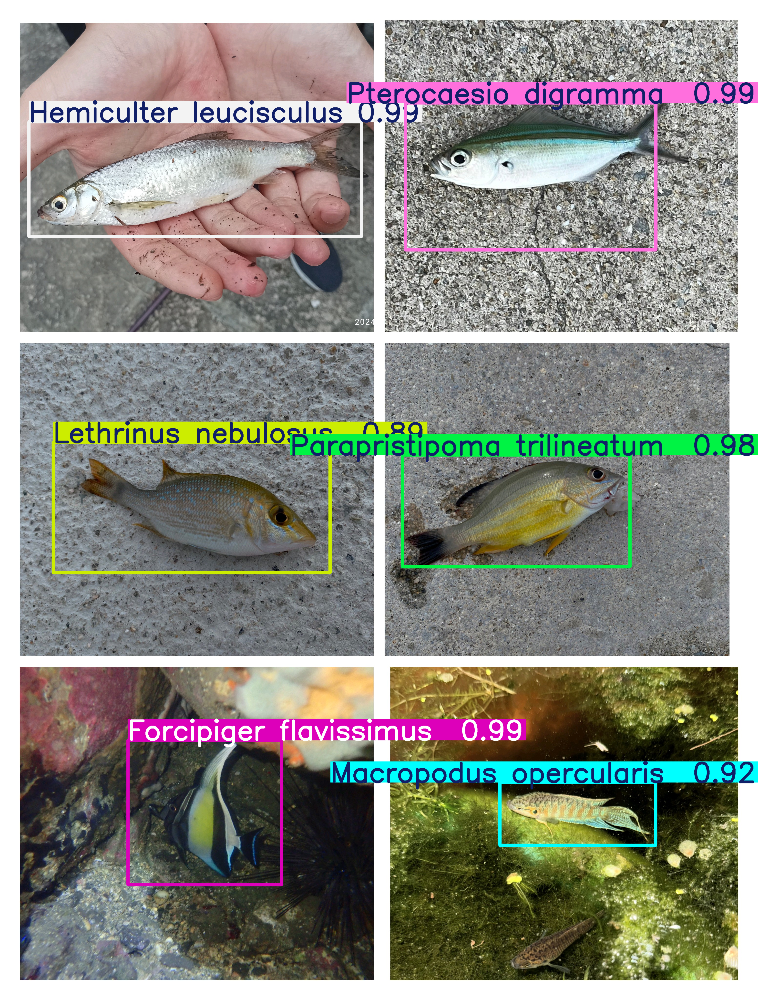

In [ ]:
# detect.py
# 適用：Google Colab + 本機（Windows/Mac/Linux）

!pip install ultralytics

import os
import cv2
from ultralytics import YOLO

def is_colab():
  """判斷是否在 Colab 環境"""
  try:
    import google.colab
    return True
  except ImportError:
    return False

def main():
  running_in_colab = is_colab()

  if running_in_colab:
    # 1.掛載 Google Drive
    from google.colab import drive
    drive.mount('/content/drive')

    # 2.Colab 專案根目錄
    project_dir = "/content/drive/MyDrive/LEGO"

  else:
    # 2.本機專案根目錄（假設 detect.py 與 runs/ 在同層）
    project_dir = os.path.dirname(os.path.abspath(__file__))

  print(f"【執行環境】：{'Colab' if running_in_colab else '本機'}")
  print(f"【專案路徑】：{project_dir}")

  # 3.模型路徑
  model_path = os.path.join(project_dir, "runs", "custom_train_exp", "weights", "best.pt")

  # 4.載入 YOLO 模型
  model = YOLO(model_path)

  # 5.測試圖片
  img_path = os.path.join(project_dir, "test3.jpg")

  # 6.執行偵測
  results = model(img_path)

  # 7.取得畫好的圖片
  annotated_img = results[0].plot()

  # === 新增：輸出 JPEG 檔 ===
  out_path = os.path.join(project_dir, "test3_detected.jpg")
  cv2.imwrite(out_path, annotated_img)
  print(f"已輸出偵測結果：{out_path}")

  # 8.顯示圖片（Colab / 本機各用不同方式）
  if running_in_colab:
    from google.colab.patches import cv2_imshow
    cv2_imshow(annotated_img)
  else:
    cv2.imshow("YOLO Detection", annotated_img)
    print("按任意鍵關閉視窗...")
    cv2.waitKey(0)
    cv2.destroyAllWindows()


if __name__ == "__main__":
  main()
